**Sumit** **Yadav**

CSE-AI "D"


202501100300262


Case Study-> 4

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
df=pd.read_csv("/content/Online_Retail.csv")

In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df.shape

(142654, 8)

In [ ]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,1
Description,471
Quantity,1
InvoiceDate,1
UnitPrice,1
CustomerID,45162
Country,1


In [ ]:
df.duplicated().sum()

np.int64(1288)

In [ ]:
#to remove the row having null values
df=df.dropna(subset=["CustomerID"])

In [ ]:
#Converting the customer id to integer type
df["CustomerID"]=df["CustomerID"].astype(int)

In [ ]:
#to convert invoice date into date time by pandas function
#Because sometime pyth will read it as string
df["InvoiceDate"]=pd.to_datetime(df["InvoiceDate"])

In [ ]:
#Removing those whose are cancelled and also removing those which are invalid
df=df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df=df[(df["Quantity"]>0) &(df["UnitPrice"]>0)]

In [ ]:
#Calculating total amount which will be needed for RFM
df["TotalPrice"]=df["Quantity"]*df["UnitPrice"]

In [ ]:
#RFM

# We will find the latest date
latest_day=df["InvoiceDate"].max()

#Timedelta is used to add or sub days
#here it is making for rfm
latest_day=latest_day+pd.Timedelta(days=1)

#Calculating the rfm
#groupby-> will group all transactions of same customer
# agg-> to perform different mathematical calculations om diff col
# nunique-> to count unique invoices
#sum-> to sum all the money spent of the customer
#Recency -> Days since the last purchase
# Frequency -> Number of orders
# Monetary-> Total amount spent

rfm=df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (latest_day -x.max()).days,
    'InvoiceNo':"nunique",
    "TotalPrice":"sum"
})
#Rename col to 3
rfm.columns=["Recency","Frequency","Monetary"]
print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346            74          1  77183.60
12347            65          2   1187.18
12348            67          2   1120.24
12350            58          1    334.40
12352            10          5   1561.81


In [ ]:
# Log transformation on RFM dataset
#to reduce skewness
# np.log1p() -> For log transformation(used over logp() because to handle 0)
# rfm_log-> to stores the RFM data
rfm_log=np.log1p(rfm)
print(rfm_log.head())

             Recency  Frequency   Monetary
CustomerID                                
12346       4.317488   0.693147  11.253955
12347       4.189655   1.098612   7.080178
12348       4.219508   1.098612   7.022190
12350       4.077537   0.693147   5.815324
12352       2.397895   1.791759   7.354241


In [ ]:
scaler=StandardScaler()
rfm_scaled=scaler.fit_transform(rfm_log)


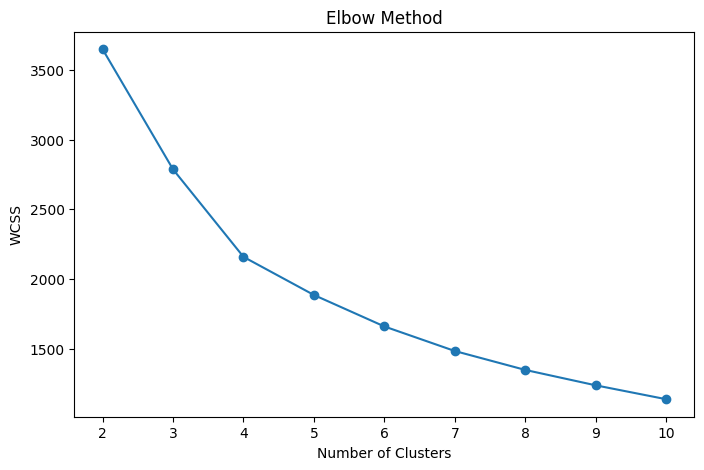

In [ ]:
#KMeans
wcss=[]
for k in range(2,11):
  model=KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10
  )
  model.fit(rfm_scaled)
  wcss.append(model.inertia_)
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), wcss, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.show()

In [ ]:
# applying kmeans
kmeans=KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)
rfm["KMeans_Cluster"]=kmeans.fit_predict(rfm_scaled)

#Used to count how many unique value occurs
print(rfm["KMeans_Cluster"].value_counts())

KMeans_Cluster
0    905
3    568
2    396
1    272
Name: count, dtype: int64


In [ ]:
# DBSCAN->

dbscan=DBSCAN(eps =0.8,min_samples=10)

#To apply DBSCAN clustering algo to RFM data
rfm["DBSCAN_Cluster"]=dbscan.fit_predict(rfm_scaled)

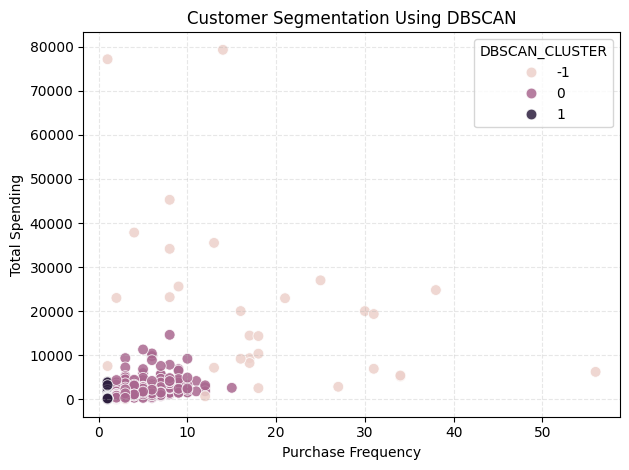

In [ ]:
sns.scatterplot(
    data = rfm,
    x="Frequency",
    y="Monetary",
    hue="DBSCAN_Cluster",

    s=60,
    alpha=0.85
)


plt.title("Customer Segmentation Using DBSCAN")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")

plt.legend(title = "DBSCAN_CLUSTER")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#PCA->

pca=PCA(n_components=2)
X_pca=pca.fit_transform(rfm_scaled)



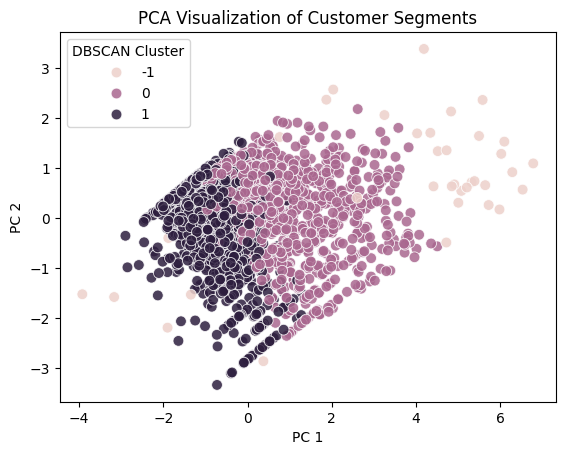

In [ ]:
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["DBSCAN_Cluster"],

    s=60,
    alpha=0.85
)

plt.title("PCA Visualization of Customer Segments")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(title = "DBSCAN Cluster")
plt.show()

In [ ]:
# TSNE->
sample_size = min(3000, len(rfm_scaled))
indices = np.random.choice(
    len(rfm_scaled),
    sample_size,
    replace=False
)

sample_data = rfm_scaled[indices]
tsne=TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
)

rfm_tsne=tsne.fit_transform(sample_data)

In [ ]:
#Customer Persona

kmeans_summary=rfm.groupby("KMeans_Cluster").agg({
    "Recency":"mean",
    "Frequency":"mean",
    "Monetary": "mean"
}).round(2)
print("\nK-Means Customer Personas",kmeans_summary)


K-Means Customer Personas                 Recency  Frequency  Monetary
KMeans_Cluster                              
0                 72.15       1.07    241.86
1                 12.71       7.15   4181.38
2                  7.67       1.54    469.95
3                 47.06       2.14   1145.33


In [ ]:
r_median = rfm['Recency'].median()
f_median = rfm['Frequency'].median()
m_median = rfm['Monetary'].median()


def get_persona(row):

    if (row['Recency'] <= r_median and
        row['Frequency'] >= f_median and
        row['Monetary'] >= m_median):

        return "Champions"

    elif row['Recency'] > r_median and row['Frequency'] >= f_median:

        return "At Risk Customers"

    elif row['Monetary'] >= m_median:

        return "Big Spenders"

    elif row['Recency'] <= r_median:

        return "Recent Customers"

    else:

        return "Hibernating Customers"


kmeans_summary['Persona'] = kmeans_summary.apply(
    get_persona,
    axis=1
)

print("\nFinal Customer Personas:")
print(kmeans_summary)



Final Customer Personas:
                Recency  Frequency  Monetary            Persona
KMeans_Cluster                                                 
0                 72.15       1.07    241.86  At Risk Customers
1                 12.71       7.15   4181.38          Champions
2                  7.67       1.54    469.95          Champions
3                 47.06       2.14   1145.33  At Risk Customers
